# NMOS regulated cascode

The OTA holds the summing node `d1` at V_ref1 through T1 while the ladder current sweeps the code range.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sarlib import specs as S
from sarlib.analysis import load_real, parse_op_log, eng, Report, settle_time

DATA = Path('simulation/n_cascode.sch')
c = S.cascode
SP = c.SPECS
rep = Report()

## DC sweep over the code range

v(d1) range 0.423 mV, R_in 20.9 ohm (worst local 25.1), nonlinearity 12 uV
T1 current 18.2 to 38.2 uA, OTA output 0.998 to 1.063 V


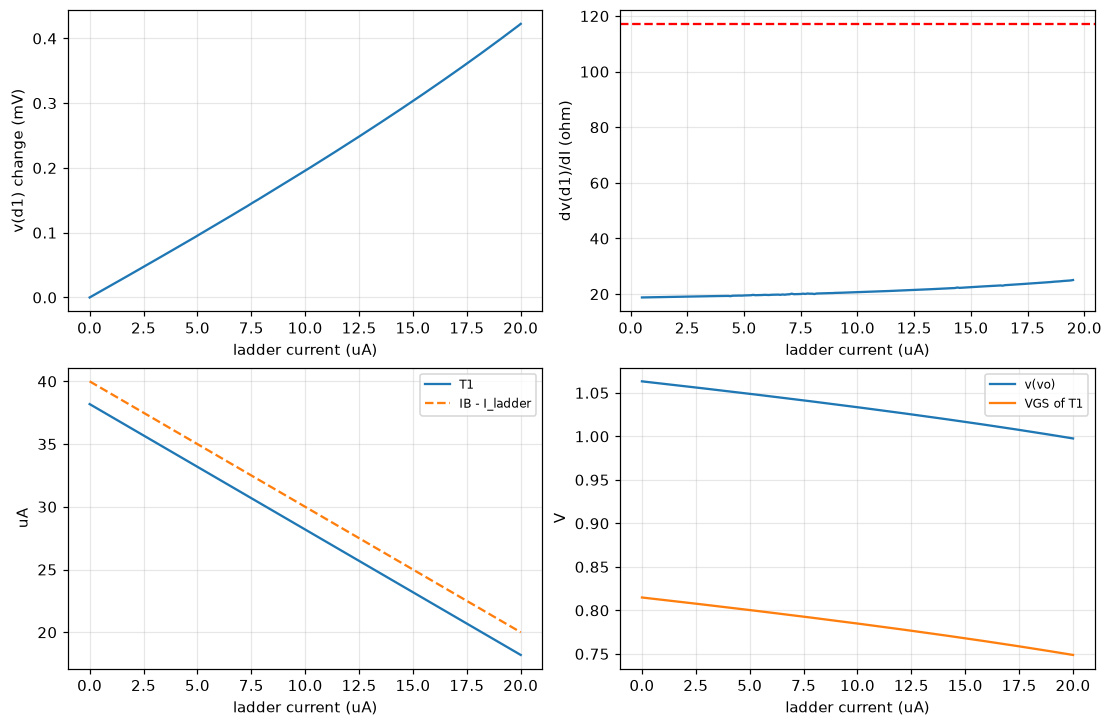

In [ ]:
ilad, (vd1, vo, id1) = load_real(DATA / 'dc_sweep.csv')
fit = np.polyfit(ilad, vd1, 1)
k = max(1, len(ilad) // 20)
rin_local = (vd1[k:] - vd1[:-k]) / (ilad[k:] - ilad[:-k])
dc_range = vd1.max() - vd1.min()
print(f'v(d1) range {1e3 * dc_range:.3f} mV, R_in {abs(fit[0]):.1f} ohm (worst local {np.abs(rin_local).max():.1f}), '
      f'nonlinearity {1e6 * np.abs(vd1 - np.polyval(fit, ilad)).max():.0f} uV')
print(f'T1 current {1e6 * id1.min():.1f} to {1e6 * id1.max():.1f} uA, OTA output {vo.min():.3f} to {vo.max():.3f} V')
rep.check('v(d1) range over codes', eng(dc_range, 'V'), f"< {SP['dc_range_mv']} mV", 1e3 * dc_range < SP['dc_range_mv'])
rep.check('R_in (DC slope)', eng(abs(fit[0]), 'ohm'), f"< {SP['rin_max']:.0f} ohm", abs(fit[0]) < SP['rin_max'])
rep.check('T1 minimum current', eng(id1.min(), 'A'), f"> {SP['t1_min_ua']} uA", 1e6 * id1.min() > SP['t1_min_ua'])
copies
il = 1e6 * ilad
fig, ax = plt.subplots(2, 2, figsize=(10, 6.5))
ax[0, 0].plot(il, 1e3 * (vd1 - vd1[0])); ax[0, 0].set(xlabel='ladder current (uA)', ylabel='v(d1) change (mV)')
ax[0, 1].plot(0.5e6 * (ilad[k:] + ilad[:-k]), rin_local); ax[0, 1].axhline(SP['rin_max'], c='r', ls='--')
ax[0, 1].set(xlabel='ladder current (uA)', ylabel='dv(d1)/dI (ohm)')
ax[1, 0].plot(il, 1e6 * id1, label='T1'); ax[1, 0].plot(il, 1e6 * (S.I_BIAS - ilad), '--', label='IB - I_ladder')
ax[1, 0].set(xlabel='ladder current (uA)', ylabel='uA'); ax[1, 0].legend(fontsize=8)
ax[1, 1].plot(il, vo, label='v(vo)'); ax[1, 1].plot(il, vo - vd1, label='VGS of T1')
ax[1, 1].set(xlabel='ladder current (uA)', ylabel='V'); ax[1, 1].legend(fontsize=8)
plt.show()

## Loop gain

T = −v(d1)/v(vfb) at three ladder currents.

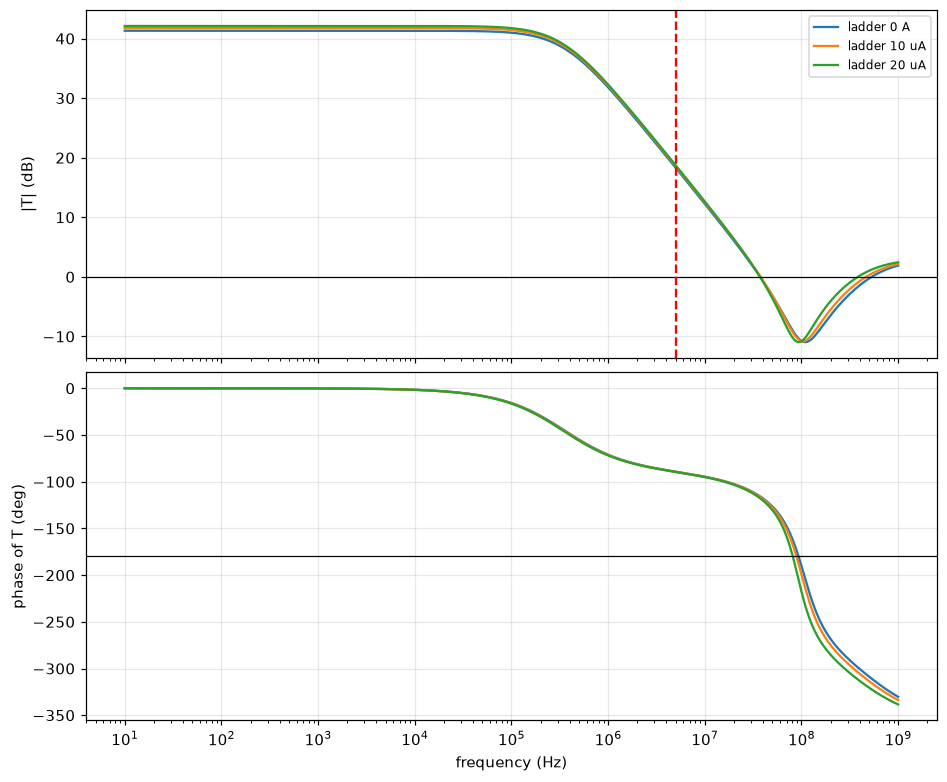

,dc_gain_dB,fu,PM_deg,f180,GM_dB,min_1pT,at
0 A,41.31,37.4 MHz,64.25,93.3 MHz,10.33,0.67,75.9 MHz
10 uA,41.77,37.8 MHz,63.16,88.7 MHz,10.15,0.66,72.4 MHz
20 uA,42.11,37.2 MHz,62.31,81.2 MHz,10.23,0.66,69.2 MHz


In [3]:
def margins(f, T):
    db = 20 * np.log10(np.abs(T))
    ph = np.degrees(np.unwrap(np.angle(T)))
    ph -= 360 * np.round(ph[0] / 360)
    lf = np.log10(f)
    i = np.where((db[:-1] >= 0) & (db[1:] < 0))[0][0]
    w = -db[i] / (db[i + 1] - db[i])
    j = np.where((ph[:-1] > -180) & (ph[1:] <= -180))[0][0]
    w2 = (-180 - ph[j]) / (ph[j + 1] - ph[j])
    kmin = int(np.argmin(np.abs(1 + T)))
    return dict(dc_gain_dB=db[0], fu=10 ** (lf[i] + w * (lf[i + 1] - lf[i])), PM_deg=180 + ph[i] + w * (ph[i + 1] - ph[i]),
                f180=10 ** (lf[j] + w2 * (lf[j + 1] - lf[j])), GM_dB=-(db[j] + w2 * (db[j + 1] - db[j])),
                min_1pT=abs(1 + T[kmin]), at=f[kmin], db=db, ph=ph, f=f)

LOOP = {}
for lvl, name in zip(c.LOOP_LEVELS, ('loop_0.csv', 'loop_10u.csv', 'loop_20u.csv')):
    f, (db, ph) = load_real(DATA / name)
    LOOP[lvl] = margins(f, 10 ** (db / 20) * np.exp(1j * np.deg2rad(ph)))
    m = LOOP[lvl]
    rep.check(f'phase margin @ {eng(lvl, "A")}', f"{m['PM_deg']:.1f} deg", f">= {SP['pm_min']:.0f} deg", m['PM_deg'] >= SP['pm_min'])
    rep.check(f'unity-gain freq @ {eng(lvl, "A")}', eng(m['fu'], 'Hz'), f">= {eng(SP['fu_min'], 'Hz')}", m['fu'] >= SP['fu_min'])
    rep.check(f'min |1+T| @ {eng(lvl, "A")}', f"{m['min_1pT']:.3f}", f">= {SP['min_1pt']}", m['min_1pT'] >= SP['min_1pt'])

fig, ax = plt.subplots(2, 1, figsize=(8.5, 7), sharex=True)
for lvl, m in LOOP.items():
    ax[0].semilogx(m['f'], m['db'], label=f'ladder {eng(lvl, "A")}')
    ax[1].semilogx(m['f'], m['ph'])
ax[0].axhline(0, c='k', lw=0.8); ax[0].axvline(SP['fu_min'], c='r', ls='--'); ax[0].set_ylabel('|T| (dB)'); ax[0].legend(fontsize=8)
ax[1].axhline(-180, c='k', lw=0.8); ax[1].set(xlabel='frequency (Hz)', ylabel='phase of T (deg)')
plt.show()
pd.DataFrame({eng(l, 'A'): {k: (eng(v, 'Hz') if k in ('fu', 'f180', 'at') else round(v, 2)) for k, v in m.items()
                            if k not in ('db', 'ph', 'f')} for l, m in LOOP.items()}).T

## Input impedance

|Z_in| 25.4 ohm at low frequency, 119.4 ohm at F_CLK, peak 7.33 kohm at 66.1 MHz


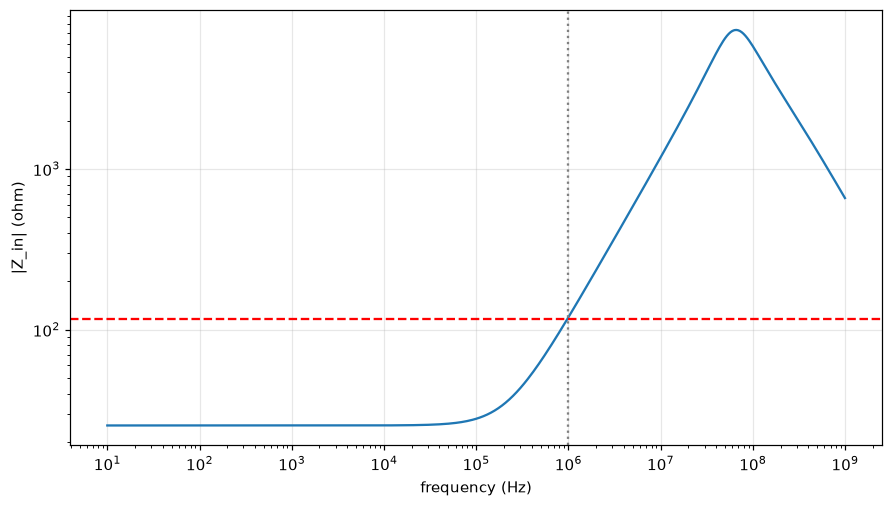

In [4]:
f, (z,) = load_real(DATA / 'zin.csv')
zmax = z[f <= S.F_CONV].max()
print(f'|Z_in| {z[0]:.1f} ohm at low frequency, {np.interp(np.log10(S.F_CONV), np.log10(f), z):.1f} ohm at F_CLK, '
      f'peak {eng(z.max(), "ohm")} at {eng(f[np.argmax(z)], "Hz")}')
rep.check('worst |Z_in| up to F_CLK', eng(zmax, 'ohm'), f"< {SP['rin_max']:.0f} ohm", zmax < SP['rin_max'])
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.loglog(f, z); ax.axhline(SP['rin_max'], c='r', ls='--'); ax.axvline(S.F_CONV, c='gray', ls=':')
ax.set(xlabel='frequency (Hz)', ylabel='|Z_in| (ohm)')
plt.show()

## Step response

Error on v(d1) against its final value (mean of the last 5 % of the window) after a 10 uA ladder step.

static shift 0.196 mV (R_in 19.6 ohm), peak 32.1 mV, settles to 0.5 mV in 17.1 ns


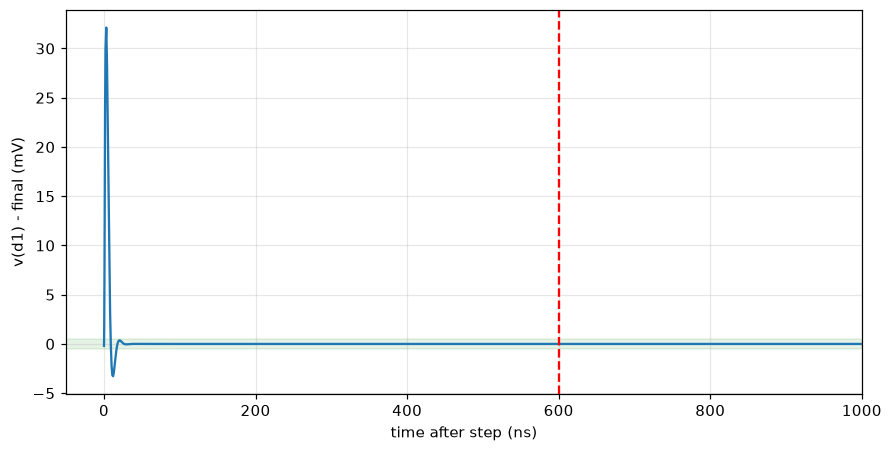

In [5]:
st = c.STEP
t, (v, *_) = load_real(DATA / 'tran.csv')
pre = t < st['t0']
win = (t >= st['t0']) & (t <= st['t_end'])
tw, vw = t[win], v[win]
last = tw >= st['t_end'] - 0.05 * (st['t_end'] - st['t0'])
final = np.trapezoid(vw[last], tw[last]) / (tw[last][-1] - tw[last][0])
dev = vw - final
shift = final - np.trapezoid(v[pre], t[pre]) / (t[pre][-1] - t[pre][0])
err = abs(np.interp(st['t0'] + SP['t_settle'], tw, dev))
print(f"static shift {1e3 * shift:.3f} mV (R_in {abs(shift / st['istep']):.1f} ohm), peak {1e3 * np.abs(dev).max():.1f} mV, "
      f"settles to {SP['tran_err_mv']} mV in {eng(settle_time(tw, dev, 0.0, 1e-3 * SP['tran_err_mv']), 's')}")
rep.check(f"error at {eng(SP['t_settle'], 's')}", eng(err, 'V'), f"< {SP['tran_err_mv']} mV", 1e3 * err < SP['tran_err_mv'])
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(1e9 * (tw - st['t0']), 1e3 * dev); ax.axhspan(-SP['tran_err_mv'], SP['tran_err_mv'], color='g', alpha=0.1)
ax.axvline(1e9 * SP['t_settle'], c='r', ls='--'); ax.set(xlim=(-50, 1000), xlabel='time after step (ns)', ylabel='v(d1) - final (mV)')
plt.show()

## Operating point at 10 uA

In [6]:
vals = parse_op_log(DATA / 'output.log')
node = lambda n: 0.0 if n == '0' else vals[f'v({n})'.lower()]
devices = {'T1': ('m.xm2.msky130_fd_pr__nfet_01v8', 'Vsum_out', 'Vg', 'd1'),
           'T3': ('m.xm1.msky130_fd_pr__nfet_01v8', 'd1', 'Vbn', '0')}
op = pd.DataFrame({k: dict(VDS=node(d) - node(s), VGS=node(g) - node(s), VDSAT=vals[f'@{p}[vdsat]'])
                   for k, (p, d, g, s) in devices.items()}).T
op['margin'] = op.VDS - op.VDSAT
rep.check('min VDS - VDSAT, T1 and T3', eng(op.margin.min(), 'V'), '>= 50 mV', op.margin.min() >= 0.05)
op.round(3)

,VDS,VGS,VDSAT,margin
T1,0.251,0.785,0.167,0.084
T3,0.249,0.712,0.151,0.098


## Summary

In [7]:
rep.table()

,check,value,spec,result
0,v(d1) range over codes,423 uV,< 2.0 mV,PASS
1,R_in (DC slope),20.9 ohm,< 117 ohm,PASS
2,T1 minimum current,18.2 uA,> 5.0 uA,PASS
3,phase margin @ 0 A,64.2 deg,>= 60 deg,PASS
4,unity-gain freq @ 0 A,37.4 MHz,>= 5 MHz,PASS
5,min |1+T| @ 0 A,0.669,>= 0.5,PASS
6,phase margin @ 10 uA,63.2 deg,>= 60 deg,PASS
7,unity-gain freq @ 10 uA,37.8 MHz,>= 5 MHz,PASS
8,min |1+T| @ 10 uA,0.661,>= 0.5,PASS
9,phase margin @ 20 uA,62.3 deg,>= 60 deg,PASS
